# Power Analysis

Here I check if I actually have enough data (90 days) to detect meaningful CPA differences between channels, and how many days I would need for smaller effects.

Input: `data/marketing_data.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from scipy import stats

daily = pd.read_csv('data/marketing_data.csv')
daily.head()

,platform,date,impressions,clicks,conversions,ad_spend,revenue,CTR,conversion_rate,CPA,ROAS
0,Google Ads,2024-01-01,21702,1000,17,3170.00,3670.88,0.046079,0.017000,186.470588,1.158006
1,Google Ads,2024-01-04,162825,7382,452,19953.23,24924.40,0.045337,0.061230,44.144314,1.249141
2,Google Ads,2024-01-05,196692,6264,310,15668.95,64727.90,0.031847,0.049489,50.545000,4.130966
3,Google Ads,2024-01-06,139158,3061,118,3887.47,15835.46,0.021997,0.038549,32.944661,4.073462
4,Google Ads,2024-01-07,238097,9087,340,21959.64,49123.74,0.038165,0.037416,64.587176,2.237001


## Simulate power for detecting CPA differences

The idea: if two channels really differ in CPA by some percentage, how often would a t-test on `n_days` of data actually catch that difference (reject the null)? I simulate this many times to estimate the probability, which is the statistical power.

Channel A's daily CPA is simulated as a normal distribution around a base CPA. Channel B is the same, but shifted by the true difference I am testing for. Both are floored at 50% of the base CPA, so I do not get unrealistic negative or near zero costs.

In [2]:
def empirical_power_cpa(true_diff_pct, base_cpa, n_days, n_sim=1000, alpha=0.05, rng=None):
    """Estimate the power to detect a true_diff_pct difference in CPA with n_days of data per channel."""
    if rng is None:
        rng = np.random.default_rng()

    std = base_cpa * 0.15
    floor = base_cpa * 0.5

    # simulate all n_sim experiments at once: shape (n_sim, n_days)
    sample_a = rng.normal(base_cpa, std, size=(n_sim, n_days))
    sample_b = rng.normal(base_cpa * (1 + true_diff_pct), std, size=(n_sim, n_days))
    sample_a = np.maximum(sample_a, floor)
    sample_b = np.maximum(sample_b, floor)

    # t-test per simulation (row), all at once
    _, p_values = stats.ttest_ind(sample_a, sample_b, axis=1)

    return (p_values < alpha).mean()

In [3]:
base_cpa = daily['CPA'].mean()
print(f'Using overall average CPA as the baseline: ${base_cpa:.2f}')

effect_sizes_pct = [5, 10, 15, 20]
n_days_list = [30, 60, 90, 120, 180]

rows = []
for effect_pct in effect_sizes_pct:
    for n_days in n_days_list:
        power = empirical_power_cpa(effect_pct / 100, base_cpa, n_days)
        rows.append({'effect_size_pct': effect_pct, 'n_days': n_days, 'power': power})

power_df = pd.DataFrame(rows)
power_df.pivot(index='n_days', columns='effect_size_pct', values='power').round(3)

Using overall average CPA as the baseline: $40.50


effect_size_pct,5,10,15,20
n_days,,,,
30,0.243,0.704,0.965,1.0
60,0.423,0.951,1.000,1.0
90,0.604,0.996,1.000,1.0
120,0.763,0.998,1.000,1.0
180,0.881,1.000,1.000,1.0


### Power curves

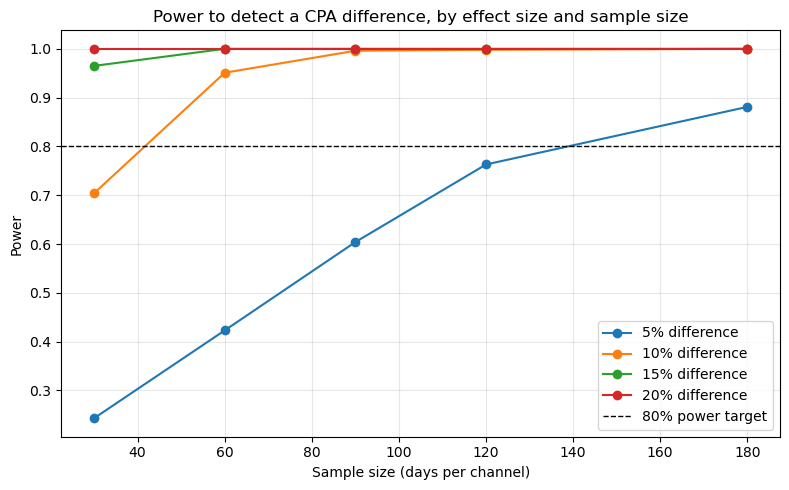

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))

for effect_pct in effect_sizes_pct:
    subset = power_df[power_df['effect_size_pct'] == effect_pct]
    ax.plot(subset['n_days'], subset['power'], marker='o', label=f'{effect_pct}% difference')

ax.axhline(0.8, color='black', linestyle='--', linewidth=1, label='80% power target')
ax.set_xlabel('Sample size (days per channel)')
ax.set_ylabel('Power')
ax.set_title('Power to detect a CPA difference, by effect size and sample size')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('power_analysis_cpa.png', dpi=150, bbox_inches='tight')
plt.show()

## Minimum sample size for 80% power

For each effect size, I search for the smallest number of days that gets me to 80% power, then check if my current 90 days of data is enough.

In [5]:
def min_days_for_power(true_diff_pct, base_cpa, target_power=0.8, n_sim=1000, max_days=365, step=5):
    """Smallest n_days (multiple of step) that reaches target_power. None if not reached by max_days."""
    for n_days in range(step, max_days + 1, step):
        power = empirical_power_cpa(true_diff_pct, base_cpa, n_days, n_sim=n_sim)
        if power >= target_power:
            return n_days
    return None

CURRENT_DAYS = 90
target_power = 0.80

rows = []
for effect_pct in effect_sizes_pct:
    min_days = min_days_for_power(effect_pct / 100, base_cpa, target_power=target_power)
    sufficient = (min_days is not None) and (min_days <= CURRENT_DAYS)
    rows.append({
        'effect_size_pct': effect_pct,
        'min_days_needed': min_days,
        'current_data_status': 'sufficient' if sufficient else 'insufficient',
    })

min_days_df = pd.DataFrame(rows)
min_days_df

,effect_size_pct,min_days_needed,current_data_status
0,5,145,insufficient
1,10,40,sufficient
2,15,20,sufficient
3,20,10,sufficient


## Is my current 90 days of data enough for the differences I actually found?

In `statistical_analysis.ipynb`, all 3 CPA channel pairs came out significant, even after FDR correction. Here I check how much power I actually had to detect those specific observed differences, using 90 days and the smaller of the two channel means as the baseline.

In [6]:
mean_cpa_by_channel = daily.groupby('platform')['CPA'].mean()
print('Average CPA by channel:')
print(mean_cpa_by_channel.round(2))
print()

channels = sorted(daily['platform'].unique())
for group_a, group_b in combinations(channels, 2):
    mean_a, mean_b = mean_cpa_by_channel[group_a], mean_cpa_by_channel[group_b]
    baseline = min(mean_a, mean_b)
    observed_diff_pct = abs(mean_a - mean_b) / baseline

    power_at_90 = empirical_power_cpa(observed_diff_pct, baseline, CURRENT_DAYS)

    print(f'{group_a} vs {group_b}: observed difference = {observed_diff_pct:.1%}, '
          f'power with {CURRENT_DAYS} days = {power_at_90:.1%}')

    if power_at_90 < target_power:
        needed = min_days_for_power(observed_diff_pct, baseline, target_power=target_power)
        print(f'   -> below 80% power target, would need about {needed} days')
    else:
        print('   -> already above the 80% power target, 90 days is enough for this pair')

Average CPA by channel:
platform
Google Ads    57.54
Meta Ads      34.76
TikTok Ads    27.08
Name: CPA, dtype: float64

Google Ads vs Meta Ads: observed difference = 65.5%, power with 90 days = 100.0%
   -> already above the 80% power target, 90 days is enough for this pair
Google Ads vs TikTok Ads: observed difference = 112.4%, power with 90 days = 100.0%
   -> already above the 80% power target, 90 days is enough for this pair
Meta Ads vs TikTok Ads: observed difference = 28.4%, power with 90 days = 100.0%
   -> already above the 80% power target, 90 days is enough for this pair


### Key insights

With my overall average CPA as the baseline, I would need about 140 days of data to reliably (80% power) catch a 5% CPA difference between two channels, but only 40 days for a 10% difference, and even less for bigger gaps. So 90 days is only borderline for very small effects, but comfortable for anything 10% or larger.

The CPA differences I actually observed between channels are much bigger than that (roughly 28% to 112% apart, see `statistical_analysis.ipynb`). Because of that, the power to detect those specific differences with 90 days of data comes out at essentially 100% for every pair. In other words, 90 days was already more than enough for what I found, I was not close to underpowered here.

The one thing to flag for the memo: this power analysis is about detecting differences that are still roughly this large. If I want to catch a smaller shift in the future (say, a 5% CPA change after a small budget adjustment), I would need noticeably more days of data than what I currently have.